<a href="https://colab.research.google.com/github/AnjalyKuriakose98/fake-news-detection-NLP/blob/main/Week3_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_news_2.csv to cleaned_news_2.csv


In [5]:
import pandas as pd

df = pd.read_csv("cleaned_news_2.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (44689, 4)
Columns: ['title', 'text', 'label', 'processed_text']


,title,text,label,processed_text
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,0,donald trump sends embarrassing new year eve m...
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,0,drunk bragging trump staffer started russian c...
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",0,sheriff david clarke becomes internet joke thr...
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",0,trump obsessed even obama name coded website i...
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,0,pope francis called donald trump christmas spe...


In [6]:
from sklearn.model_selection import train_test_split    #prepare training and testing data
from sklearn.feature_extraction.text import TfidfVectorizer

df = df.dropna(subset=["processed_text", "label"])
df = df[df["processed_text"].str.strip() != ""]

X = df["processed_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training:", X_train_tfidf.shape)
print("Testing:", X_test_tfidf.shape)

Training: (35744, 5000)
Testing: (8936, 5000)


In [7]:
from sklearn.linear_model import LogisticRegression   #training 3 ML models
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(name, "training completed")

Logistic Regression training completed
Naive Bayes training completed
SVM training completed


In [8]:
from sklearn.metrics import (       #compare model performance
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models.items():

    predictions = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted"
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9880,0.9880,0.9880,0.9880
1,Naive Bayes,0.9335,0.9335,0.9335,0.9335
2,SVM,0.9957,0.9957,0.9957,0.9957


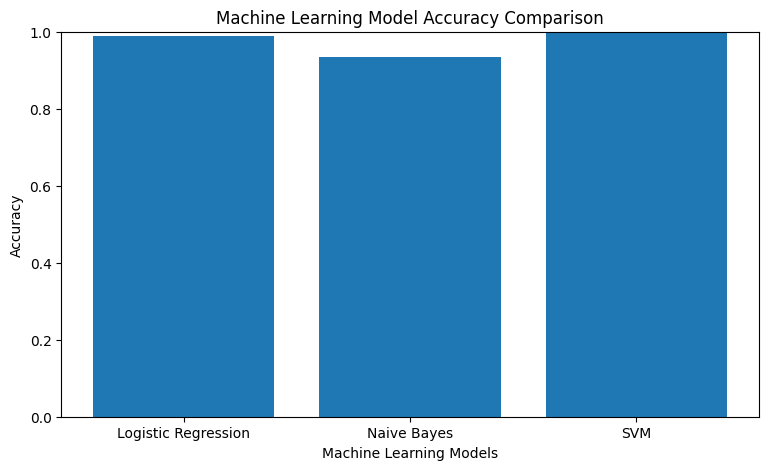

In [9]:
import matplotlib.pyplot as plt   #Create a comparison graph

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.savefig(
    "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
best_row = results_df.loc[           #Find the best model
    results_df["F1 Score"].idxmax()
]

best_model_name = best_row["Model"]
best_model = models[best_model_name]

print("Best model:", best_model_name)
print("F1 Score:", round(best_row["F1 Score"], 4))

Best model: SVM
F1 Score: 0.9957


In [11]:
predictions = best_model.predict(X_test_tfidf) #Examine incorrect predictions

errors = pd.DataFrame({
    "Article": X_test.to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": predictions
})

errors = errors[
    errors["Actual"] != errors["Predicted"]
]

print("Total incorrect predictions:", len(errors))

display(errors.head(10))

Total incorrect predictions: 38


,Article,Actual,Predicted
77,trump washington foreign policy speech reuters...,1,0
236,factbox critics lament trump climate move supp...,1,0
579,u judge approves court police accord ferguson ...,1,0
700,waiting green cards indian visa holders see ho...,1,0
1359,live feed hearing senator sessions include rad...,0,1
1364,obama says trump immigration move cruel requir...,1,0
1438,emmy winners throw jabs trump spicer wheels sp...,1,0
1447,u chief justice alarmed trump administration i...,1,0
3013,russia hits obama hard reaching really terrify...,0,1
3176,north korea blinks threats potus mad dog matti...,0,1


In [12]:
import joblib

joblib.dump(best_model, "best_model_week3.pkl")
joblib.dump(tfidf, "tfidf_week3.pkl")

results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

errors.to_csv(
    "misclassified_articles.csv",
    index=False
)

print("Week 3 files saved successfully!")

Week 3 files saved successfully!
